# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Стик Назарій'      # прізвище та ім'я
GROUP        = 'ШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 17       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Стик Назарій | ШІ-32 | номер 17


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 17   ·   Стик Назарій   ·   ШІ-32

   Ринок:  Volyn
   Товар:  курятина   (у наборі даних: Meat (chicken, whole) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | **28.10.2026** |
| **Підпис** | **Стик Назарій** |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду

import pandas as pd

# Завантажуємо весь набір і робимо стовпець дати (перше число місяця)
prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

# Вибираємо тільки свій ринок і товар
raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
       .sort_values('date')
       .set_index('date')['ціна'])
print('Рядків у сирому ряді:', len(raw), '| з них унікальних дат:', raw.index.nunique())

# Будуємо повну місячну сітку і накладаємо на неї ряд
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')   # MS = month start
s = raw.reindex(grid)
s.index.name = 'date'

# Рахуємо пропуски
missing = s[s.isna()].index
print('Місяців у сітці:', len(grid))
print('Мають вимір:    ', s.notna().sum())
print('Пропусків:      ', s.isna().sum(), '→', [d.strftime('%m.%Y') for d in missing])

# Перевіряємо, чи пропуск лише в моєму ряді, чи в усьому наборі
for d in missing:
    n = ((prices['рік'] == d.year) & (prices['місяць'] == d.month)).sum()
    print(f'Записів у ВСЬОМУ наборі за {d:%m.%Y}: {n}')
print('\nКількість записів у наборі по місяцях навколо пропуску:')
print(prices.groupby('date').size().loc['2017-06':'2017-10'])

print('\nМій ряд навколо пропуску:')
print(s.loc['2017-06':'2017-10'])

Рядків у сирому ряді: 45 | з них унікальних дат: 45
Місяців у сітці: 46
Мають вимір:     45
Пропусків:       1 → ['08.2017']
Записів у ВСЬОМУ наборі за 08.2017: 0

Кількість записів у наборі по місяцях навколо пропуску:
date
2017-06-01    650
2017-07-01    650
2017-09-01    650
2017-10-01    650
dtype: int64

Мій ряд навколо пропуску:
date
2017-06-01    45.9433
2017-07-01    50.2500
2017-08-01        NaN
2017-09-01    57.3033
2017-10-01    57.0467
Freq: MS, Name: ціна, dtype: float64


**Висновок до завдання 1:**

У варіанті 17 (Volyn, Meat (chicken, whole) - Retail) є 45 унікальних записів за період з березня 2014 до грудня 2017 року, який охоплює 46 місяців. Дані відсутні лише за серпень 2017 року. Це не пов'язано з Волинню чи курятиною, оскільки за цей місяць у всьому наборі немає записів, хоча за липень і вересень є по 650. Найімовірніше, дані за серпень не були зібрані або опубліковані. Якщо не побудувати повну часову сітку, пропуск можна не помітити, що призведе до помилок у методах сезонного аналізу, ACF та ARIMA. Тому спочатку потрібно побудувати повну сітку, а потім проводити аналіз.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску

gap = s[s.isna()].index[0]   # 2017-08-01

fills = pd.Series({
    'Перенесення останнього (ffill)': s.ffill()[gap],
    'Лінійна інтерполяція':           s.interpolate('linear')[gap],
    'Кубічний сплайн':                s.interpolate('spline', order=3)[gap],
}).round(2)
print(f'Пропуск {gap:%m.%Y}, сусіди: 07.2017 = {s["2017-07-01"]:.2f}, 09.2017 = {s["2017-09-01"]:.2f}\n')
print(fills.to_string())

# Обрана лінійна інтерполяція, далі використовуємо ряд y
y = s.interpolate('linear')
print('\nПропусків після заповнення:', y.isna().sum(), '| довжина ряду:', len(y))

# Коли не можна
print(prices[prices['ринок'].isin(['Crimea', 'm. Sevastopol'])]
      .groupby('ринок')['date'].agg(['min', 'max']))

Пропуск 08.2017, сусіди: 07.2017 = 50.25, 09.2017 = 57.30

Перенесення останнього (ffill)    50.25
Лінійна інтерполяція              53.78
Кубічний сплайн                   52.29

Пропусків після заповнення: 0 | довжина ряду: 46
                     min        max
ринок                              
Crimea        2014-03-01 2014-03-01
m. Sevastopol 2014-03-01 2014-04-01


**Висновок до завдання 2:**

Пропуск за серпень 2017 року припадає на період зростання ціни з 50,25 грн у липні до 57,30 грн у вересні. Для заповнення можна використати ffill (50,25 грн), лінійну інтерполяцію (53,78 грн) або кубічний сплайн (52,29 грн). Обрано лінійну інтерполяцію, оскільки пропуск лише один і є реальні дані з обох боків. Ffill не враховує зростання ціни, а сплайн для одного пропуску зайвий. Також цей метод використовується в Orange, тому результати будуть однаковими.  
Не варто заповнювати пропуски, якщо вони пов'язані зі значними змінами. Наприклад, у Crimea дані є лише за березень 2014 року, а в m. Sevastopol - за березень і квітень. Після анексії збір даних припинився, тому заповнення решти місяців означало б вигадування цін.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

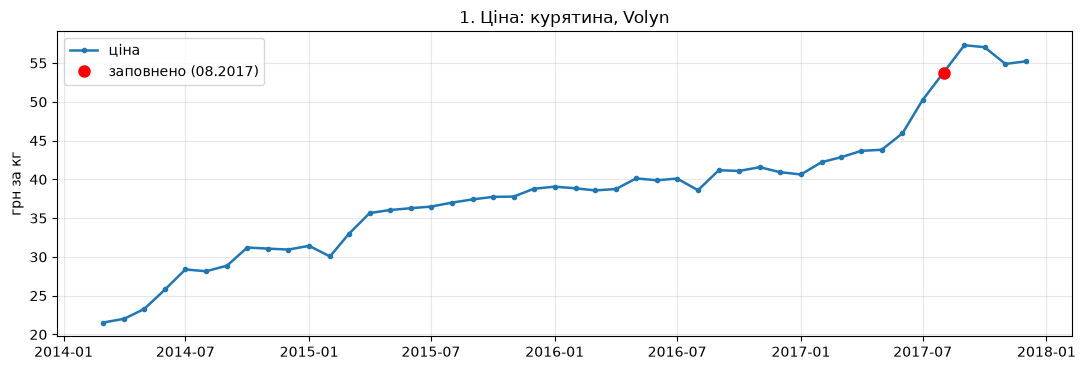

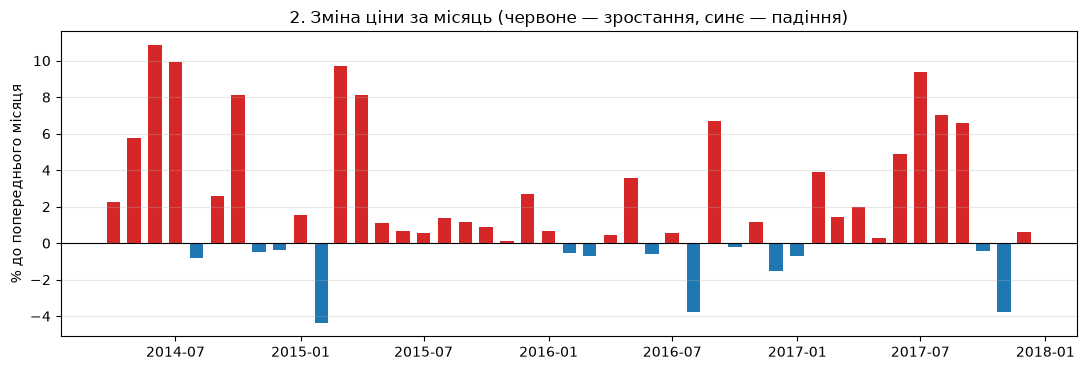

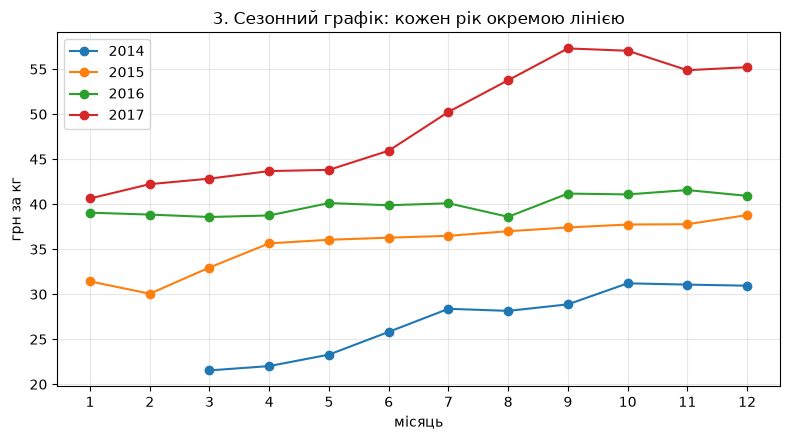

Зростання за кожен рік, %:
date
2014    43.7
2015    23.4
2016     4.8
2017    35.9
Name: ціна, dtype: float64
Найбільше зростання за місяць: 10.8% (06.2014)
Найбільше падіння за місяць:   -4.3% (02.2015)


In [5]:
# Завдання 3. Візуальна розвідка
import matplotlib.pyplot as plt

# ціна в часі 
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(y.index, y.values, marker='o', ms=3, lw=1.8, label='ціна')
ax.plot(gap, y[gap], 'o', color='red', ms=8, label='заповнено (08.2017)')
ax.set_title(f'1. Ціна: {GOOD_UA}, {MARKET}')
ax.set_ylabel('грн за кг'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

# зміна ціни за місяць
pct = y.pct_change() * 100
colors = ['tab:red' if v > 0 else 'tab:blue' for v in pct.fillna(0)]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(pct.index, pct.values, width=20, color=colors)
ax.axhline(0, color='black', lw=.8)
ax.set_title('2. Зміна ціни за місяць (червоне — зростання, синє — падіння)')
ax.set_ylabel('% до попереднього місяця'); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

# сезонний графік
fig, ax = plt.subplots(figsize=(8, 4.5))
for year, part in y.groupby(y.index.year):
    ax.plot(part.index.month, part.values, marker='o', label=str(year))
ax.set_xticks(range(1, 13)); ax.set_xlabel('місяць'); ax.set_ylabel('грн за кг')
ax.set_title('3. Сезонний графік: кожен рік окремою лінією')
ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()


print('Зростання за кожен рік, %:')
print((y.groupby(y.index.year).agg(lambda v: (v.iloc[-1] / v.iloc[0] - 1) * 100)).round(1))
print(f'Найбільше зростання за місяць: {pct.max():.1f}% ({pct.idxmax():%m.%Y})')
print(f'Найбільше падіння за місяць:   {pct.min():.1f}% ({pct.idxmin():%m.%Y})')

**Висновок до завдання 3:**

Графік 1 (ціна в часі) показує зміну ціни за весь період. Лінійний графік підходить для часових даних. Червона точка позначає заповнене значення за 08.2017. Ціна зросла приблизно з 21,5 до 55 грн за кг.

Графік 2 (місячна зміна у %) показує, наскільки змінювалася ціна щомісяця. Відсотки дають змогу порівнювати зміни в різні роки. Найбільше зростання становило +10,8 % у червні 2014 року, а найбільше падіння - 4,3 % у лютому 2015 року.

Графік 3 (сезонний) допомагає порівняти зміну ціни за місяцями в різні роки. Чіткого повторення сезонності немає: у 2014, 2015 та 2017 роках ціна переважно зростала навесні та влітку, а у 2016 році майже не змінювалася.

Цікавий результат: ціна зростала нерівномірно: на 44 % у 2014 році, 23 % у 2015, 5 % у 2016 та 36 % у 2017. Основне зростання у 2017 році припало на червень-вересень. При цьому падіння ціни було невеликим, до 4,3 %, тоді як зростання сягало 10 %. Це може свідчити про зміну тенденції у 2017 році.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

In [6]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


ціна = Trend + Season + Resid

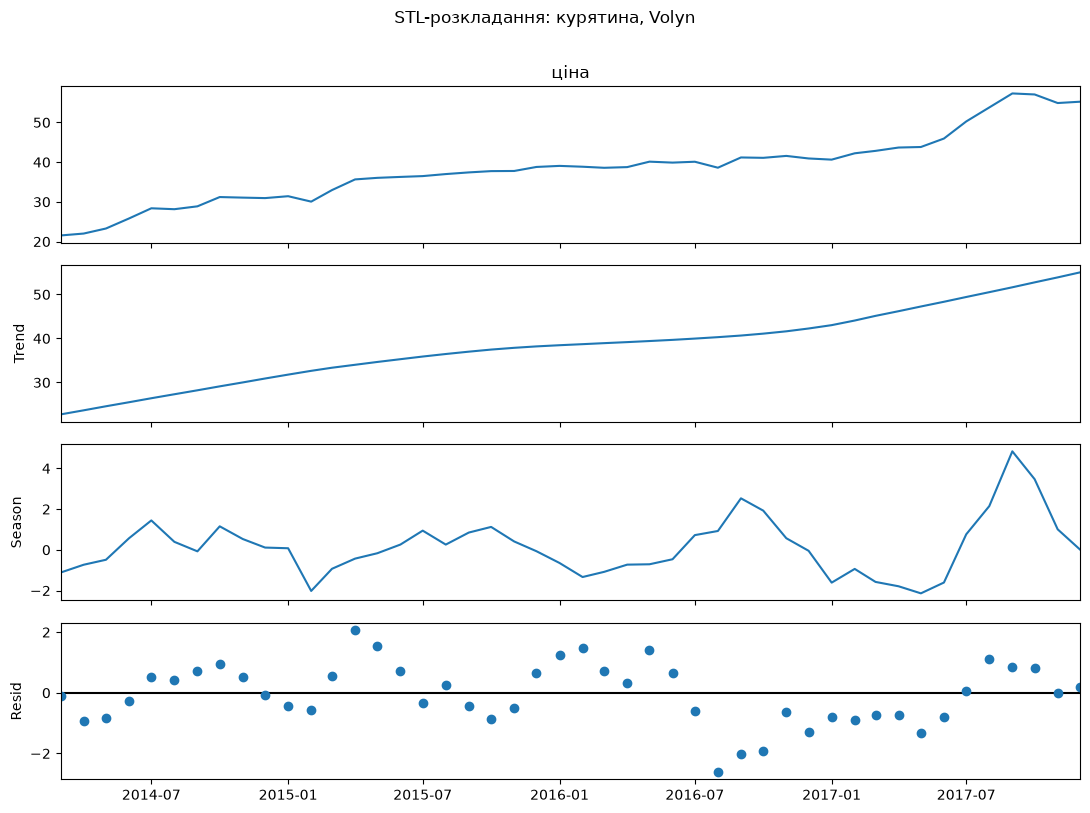

Сила сезонності F_S = 0.673
Сила тренду     F_T = 0.985
Поріг сильної сезонності: 0.64

Робастний STL: F_S = 0.045, F_T = 0.875

Сезонна складова по роках (рядки — місяці):
рік     2014  2015  2016  2017
місяць                        
1        NaN  0.08 -0.65 -1.61
2        NaN -2.02 -1.34 -0.94
3      -1.12 -0.93 -1.08 -1.58
4      -0.73 -0.43 -0.73 -1.79
5      -0.49 -0.17 -0.71 -2.14
6       0.57  0.26 -0.46 -1.61
7       1.44  0.94  0.72  0.76
8       0.39  0.26  0.93  2.15
9      -0.07  0.85  2.53  4.84
10      1.15  1.12  1.92  3.47
11      0.53  0.41  0.57  1.01
12      0.11 -0.07 -0.05  0.01


In [7]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

def strength(res):
    """Сила сезонності F_S і сила тренду F_T"""
    T, S, R = res.trend, res.seasonal, res.resid
    F_S = max(0, 1 - R.var() / (S + R).var())
    F_T = max(0, 1 - R.var() / (T + R).var())
    return F_S, F_T

# Основне розкладання: STL з періодом 12
res = STL(y, period=12).fit()
fig = res.plot()
fig.set_size_inches(11, 8)
fig.suptitle(f'STL-розкладання: {GOOD_UA}, {MARKET}', y=1.01)
plt.tight_layout(); plt.show()

F_S, F_T = strength(res)
print(f'Сила сезонності F_S = {F_S:.3f}')
print(f'Сила тренду     F_T = {F_T:.3f}')
print('Поріг сильної сезонності: 0.64')

# Робастний STL, який зменшує вплив одноразових стрибків
res_rob = STL(y, period=12, robust=True).fit()
F_S_rob, F_T_rob = strength(res_rob)
print(f'\nРобастний STL: F_S = {F_S_rob:.3f}, F_T = {F_T_rob:.3f}')

# Чи повторюється сезонний ефект
seas = res.seasonal.to_frame('s').assign(рік=y.index.year, місяць=y.index.month)
print('\nСезонна складова по роках (рядки — місяці):')
print(seas.pivot(index='місяць', columns='рік', values='s').round(2))

**Висновок до завдання 4:**

Ряд розкладено методом STL на тренд, сезонність і залишки з періодом 12 місяців. Сила тренду F_T = 0.985, тобто зміни ціни майже повністю пояснюються трендом, що видно і на першому графіку. Сила сезонності F_S = 0.673, що трохи вище порога 0.64. Проте результат нестійкий, оскільки сезонні зміни не повторюються однаково щороку. Наприклад, у вересні сезонна складова зросла від -0.07 грн у 2014 році до 4.84 грн у 2017. Робастний STL дає F_S = 0.045, тобто сезонність майже відсутня. Отже, звичайний STL сприйняв стрибок ціни влітку 2017 року як сезонний ефект. Насправді ряд переважно визначається трендом, а для надійної перевірки сезонності потрібні дані за більшу кількість років.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

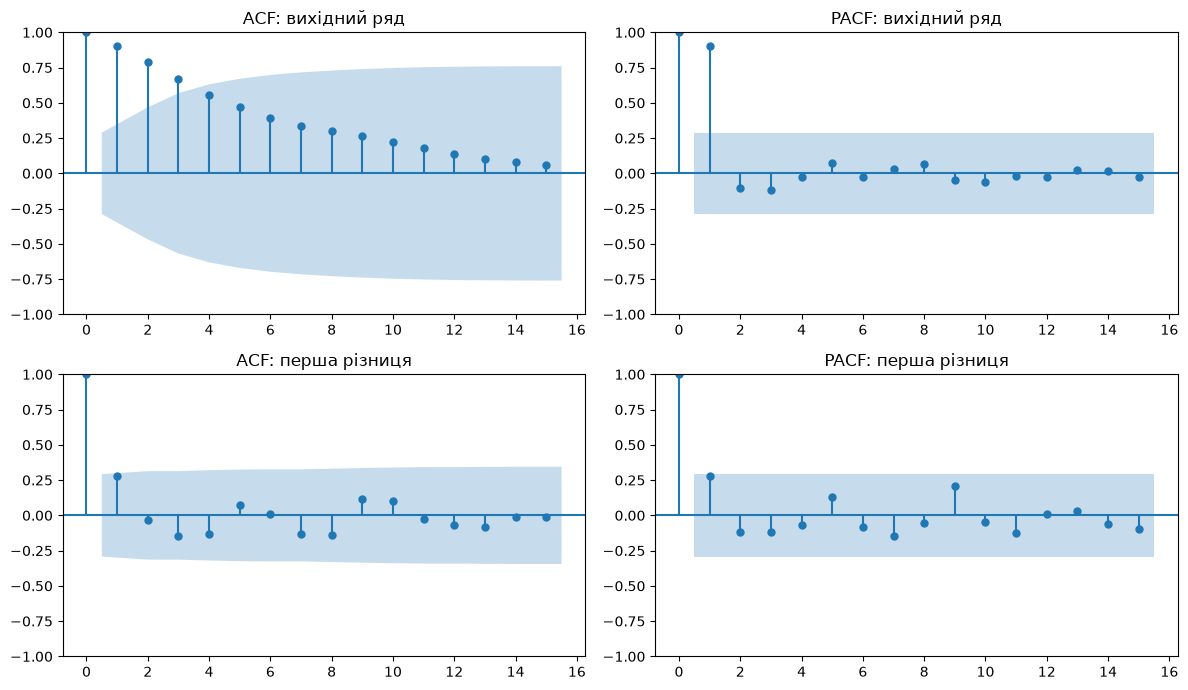

              ADF p-value    ADF висновок KPSS p-value   KPSS висновок
Вихідний ряд      0.80998  нестаціонарний         0.01  нестаціонарний
Перша різниця     0.00004    стаціонарний          0.1    стаціонарний

Примітка: KPSS повертає p лише в межах 0.01–0.10; 0.01 означає «≤ 0.01», 0.10 означає «≥ 0.10».


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_47888\2571503808.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, autolag='AIC')[1]
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_47888\2571503808.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(x, autolag='AIC')[1]


In [8]:
# Завдання 5. Стаціонарність
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

dy = y.diff().dropna() # перша різниця

# ACF і PACF до та після диференціювання
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(y,   lags=15, ax=axes[0, 0], title='ACF: вихідний ряд')
plot_pacf(y,  lags=15, ax=axes[0, 1], title='PACF: вихідний ряд', method='ywm')
plot_acf(dy,  lags=15, ax=axes[1, 0], title='ACF: перша різниця')
plot_pacf(dy, lags=15, ax=axes[1, 1], title='PACF: перша різниця', method='ywm')
plt.tight_layout(); plt.show()

# Тести ADF і KPSS
def test_row(x):
    adf_p = adfuller(x, autolag='AIC')[1]
    with warnings.catch_warnings(): # KPSS попереджає, коли p за межами таблиці 0.01–0.10
        warnings.simplefilter('ignore')
        kpss_p = kpss(x, regression='c', nlags='auto')[1]
    return {
        'ADF p-value': round(adf_p, 5),
        'ADF висновок': 'стаціонарний' if adf_p < 0.05 else 'нестаціонарний',
        'KPSS p-value': round(kpss_p, 3),
        'KPSS висновок': 'нестаціонарний' if kpss_p < 0.05 else 'стаціонарний',
    }

table = pd.DataFrame({'Вихідний ряд': test_row(y), 'Перша різниця': test_row(dy)}).T
print(table.to_string())
print('\nПримітка: KPSS повертає p лише в межах 0.01–0.10;'
      ' 0.01 означає «≤ 0.01», 0.10 означає «≥ 0.10».')

**Висновок до завдання 5:**

ACF і PACF вихідного ряду. Автокореляції високі й повільно зменшуються (0.90, 0.79, 0.67, 0.56 на перших чотирьох лагах). У PACF значущий лише перший лаг (≈ 0.92). Це свідчить про нестаціонарність ряду через наявність тренду.

ACF і PACF першої різниці. Після диференціювання автокореляції на лагах від 2 вже незначущі, а на першому лагу значення ≈ 0.28 перебуває на межі значущості. На лагу 12 значного стрибка немає, що підтверджує відсутність стійкої сезонності.

Результати тестів:

| Ряд           | ADF p-value | KPSS p-value | Висновок       |
| ------------- | ----------- | ------------ | -------------- |
| Вихідний      | 0.810       | ≤ 0.01       | Нестаціонарний |
| Перша різниця | 0.00004     | ≥ 0.10       | Стаціонарний   |

У тесті ADF нульова гіпотеза означає нестаціонарність, а в KPSS - стаціонарність. Для вихідного ряду обидва тести підтверджують нестаціонарність, а для першої різниці - стаціонарність. Отже, одного диференціювання достатньо, щоб зробити ряд стаціонарним. Це обґрунтовує вибір d = 1 для ARIMA. Через невелику кількість спостережень результати KPSS мають обмежену точність, але загальний висновок залишається незмінним.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [9]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
import numpy as np
from sklearn.model_selection import train_test_split

N_FOLDS, H = 7, 3 # 7 фолдів по 3 кроки
METHODS = ['Наївний', 'Сезонний наївний', 'Середнє', 'Дрейф']

def forecast(train, h, method):
    """Прогноз на h кроків уперед за навчальною частиною train"""
    last = train.iloc[-1]
    if method == 'Наївний':
        return np.repeat(last, h)
    if method == 'Сезонний наївний':
        return train.iloc[-12:].values[:h] # ті самі місяці торік
    if method == 'Середнє':
        return np.repeat(train.mean(), h)
    if method == 'Дрейф':
        slope = (last - train.iloc[0]) / (len(train) - 1)
        return last + slope * np.arange(1, h + 1)

def metrics(actual, pred):
    e = np.array(actual) - np.array(pred)
    return {'MAE': np.mean(np.abs(e)),
            'RMSE': np.sqrt(np.mean(e ** 2)),
            'MAPE, %': np.mean(np.abs(e / np.array(actual))) * 100}

# Ретроспективна перевірка з рухомим початком
start = len(y) - N_FOLDS * H
folds = []
for k in range(N_FOLDS):
    cut = start + k * H
    folds.append((y.iloc[:cut], y.iloc[cut:cut + H])) # (навчання, тест)

print('Фолди:')
for k, (tr, te) in enumerate(folds, 1):
    print(f'  {k}: навчання 03.2014–{tr.index[-1]:%m.%Y} ({len(tr)} міс.) → тест {te.index[0]:%m.%Y}–{te.index[-1]:%m.%Y}')

rolling = {}
for m in METHODS:
    actual = np.concatenate([te.values for tr, te in folds])
    pred   = np.concatenate([forecast(tr, H, m) for tr, te in folds])
    rolling[m] = metrics(actual, pred)
rolling = pd.DataFrame(rolling).T
print('\nРухомий початок (7 × 3):')
print(rolling.round(3))

# Випадковий поділ 75/25
t = np.arange(len(y))
tr_i, te_i = train_test_split(t, test_size=0.25, random_state=42)
tr_i, te_i = np.sort(tr_i), np.sort(te_i)
y_tr = y.iloc[tr_i]

random_split = {}
for m in METHODS:
    actual, pred = [], []
    for i in te_i:
        if m == 'Наївний':
            p = y.iloc[tr_i[np.argmin(np.abs(tr_i - i))]]
        elif m == 'Сезонний наївний':
            near = [j for j in (i - 12, i + 12) if j in tr_i]
            if not near: continue
            p = y.iloc[near[0]]
        elif m == 'Середнє':
            p = y_tr.mean()
        else:
            p = np.polyval(np.polyfit(tr_i, y_tr.values, 1), i)
        actual.append(y.iloc[i]); pred.append(p)
    random_split[m] = metrics(actual, pred)
random_split = pd.DataFrame(random_split).T

print('\nВипадковий поділ 75/25 (тестові місяці:',
      ', '.join(f'{y.index[i]:%m.%y}' for i in te_i), ')')
print(random_split.round(3))
print('\nУ скільки разів рухомий початок / випадковий поділ:')
print((rolling / random_split).round(2))

Фолди:
  1: навчання 03.2014–03.2016 (25 міс.) → тест 04.2016–06.2016
  2: навчання 03.2014–06.2016 (28 міс.) → тест 07.2016–09.2016
  3: навчання 03.2014–09.2016 (31 міс.) → тест 10.2016–12.2016
  4: навчання 03.2014–12.2016 (34 міс.) → тест 01.2017–03.2017
  5: навчання 03.2014–03.2017 (37 міс.) → тест 04.2017–06.2017
  6: навчання 03.2014–06.2017 (40 міс.) → тест 07.2017–09.2017
  7: навчання 03.2014–09.2017 (43 міс.) → тест 10.2017–12.2017

Рухомий початок (7 × 3):
                     MAE    RMSE  MAPE, %
Наївний            2.059   3.406    4.149
Сезонний наївний   6.569   8.268   13.400
Середнє           10.527  11.699   22.264
Дрейф              1.989   3.119    3.987

Випадковий поділ 75/25 (тестові місяці: 06.14, 07.14, 09.14, 11.14, 03.15, 03.16, 04.16, 05.16, 02.17, 06.17, 08.17, 11.17 )
                    MAE   RMSE  MAPE, %
Наївний           1.379  1.820    3.570
Сезонний наївний  7.886  8.775   21.487
Середнє           7.540  9.201   20.570
Дрейф             1.773  2.185

**Висновок до завдання 6:**

Найкращий базовий метод - дрейф, а наївний прогноз трохи гірший. Це пояснюється сильним висхідним трендом (F_T = 0.985), який дрейф враховує. Сезонний наївний прогноз помиляється втричі більше, оскільки стійкої сезонності немає, а ціна за попередній рік була нижчою. Найгірший результат має прогноз за середнім, бо він враховує низькі ціни 2014 року. RMSE в усіх методах вищий за MAE через різкий стрибок ціни в липні-вересні 2017 року.

Випадковий поділ 75/25 дає оптимістичніші результати: MAE наївного прогнозу становить 1,38 грн проти 2,06 грн при перевірці з рухомим початком. Це відбувається тому, що тестові місяці можуть опинитися між навчальними, і модель фактично використовує майбутні дані. Також результат залежить від випадкового вибору місяців. Тому для часових рядів правильніше використовувати перевірку з рухомим початком.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

p = 1. Модель дивиться на одну попередню зміну: «якщо минулого місяця подорожчало на 2 грн, то цього, мабуть, теж подорожчає, але, скажімо, на половину від того».  
d = 1. Спочатку переходимо від ціни до її зміни за місяць (перша різниця із завдання 5). Тепер модель прогнозує не «скільки коштуватиме», а «на скільки подорожчає».  
q = 1. Модель дивиться на одну свою попередню помилку: «минулого разу я недооцінила на 1 грн, тож трохи підкоригуюся».  

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

                           MAE   RMSE  MAPE, %
Дрейф (найкращий базис)  1.989  3.119    3.987
Наївний                  2.059  3.406    4.149
ARIMA(1,1,1)             2.615  3.967    5.170
ARIMA(0,1,0) з дрейфом   1.989  3.119    3.987

Коефіцієнти ARIMA(1,1,1):
                значення  p-value
AR (p=1)           0.488    0.084
MA (q=1)          -0.065    0.843
дисперсія шуму     1.937    0.000


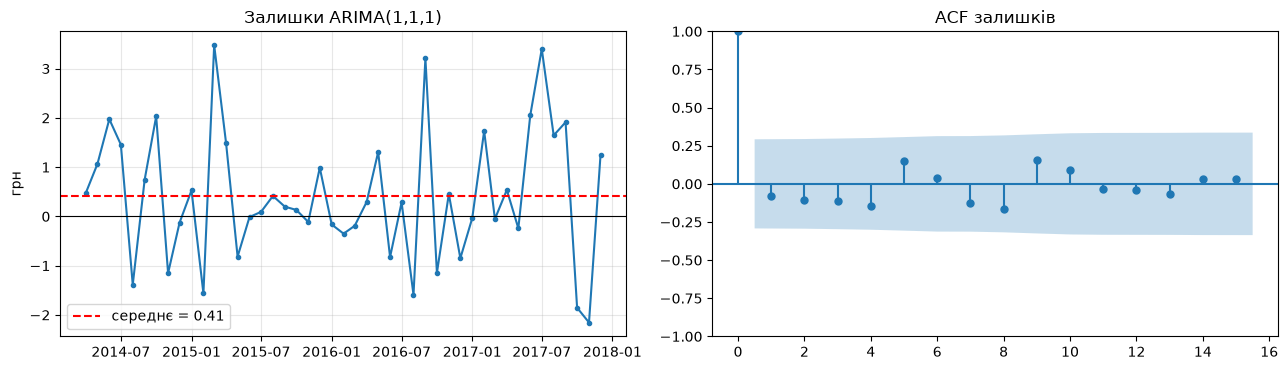


Тест Льюнга–Бокса (H0: залишки випадкові):
    lb_stat  lb_pvalue
6     3.857      0.696
12    8.504      0.745
Середнє залишків: 0.411 грн


In [10]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
warnings.filterwarnings('ignore')

def arima_forecast(train, h, order, trend='n'):
    model = ARIMA(train.values, order=order, trend=trend).fit()
    return model.forecast(h)

def evaluate(order, trend='n'):
    actual = np.concatenate([te.values for tr, te in folds])
    pred   = np.concatenate([arima_forecast(tr, H, order, trend) for tr, te in folds])
    return metrics(actual, pred)

# ARIMA(1,1,1) на тих самих 7 фолдах
results = pd.DataFrame({
    'Дрейф (найкращий базис)': rolling.loc['Дрейф'],
    'Наївний':                 rolling.loc['Наївний'],
    'ARIMA(1,1,1)':            evaluate((1, 1, 1)),
    'ARIMA(0,1,0) з дрейфом':  evaluate((0, 1, 0), trend='t'),
}).T
print(results.round(3))

# Модель на всьому ряді: коефіцієнти і залишки 
model = ARIMA(y.values, order=(1, 1, 1)).fit()
print('\nКоефіцієнти ARIMA(1,1,1):')
print(pd.DataFrame({'значення': model.params, 'p-value': model.pvalues},
                   index=['AR (p=1)', 'MA (q=1)', 'дисперсія шуму']).round(3))

resid = pd.Series(model.resid[1:], index=y.index[1:])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(resid.index, resid.values, marker='o', ms=3)
axes[0].axhline(0, color='black', lw=.8)
axes[0].axhline(resid.mean(), color='red', ls='--', label=f'середнє = {resid.mean():.2f}')
axes[0].set_title('Залишки ARIMA(1,1,1)'); axes[0].set_ylabel('грн'); axes[0].legend(); axes[0].grid(alpha=.3)
plot_acf(resid, lags=15, ax=axes[1], title='ACF залишків')
plt.tight_layout(); plt.show()

lb = acorr_ljungbox(resid, lags=[6, 12])
print('\nТест Льюнга–Бокса (H0: залишки випадкові):')
print(lb.round(3))
print(f'Середнє залишків: {resid.mean():.3f} грн')

зміна цього місяця = 0.488 × (зміна минулого місяця)
                   − 0.065 × (помилка минулого місяця)
                   + випадковість

**Висновок до завдання 7:**

ARIMA(1,1,1) працює гірше за дрейф приблизно на 30 % за MAE і навіть поступається наївному прогнозу. Тобто складніша модель не дає кращого результату. Одна з причин у тому, що модель не продовжує тренд, а її коефіцієнти статистично незначущі (AR = 0.49, p = 0.084; MA = -0.07, p = 0.84). До того ж перші фолди навчаються лише на 25 значеннях.

Вибір порядку за ACF і PACF. У завданні 5 було визначено, що достатньо одного диференціювання, тому d = 1. На графіках ACF і PACF першої різниці значущих лагів немає, тому обрано p = 0 і q = 0. Отже, найкращий варіант - ARIMA(0,1,0) з дрейфом. Вона відповідає базовому прогнозу «дрейф» і дає такі самі результати. Це підтверджує, що в ряді, крім тренду, немає вираженої структури для складнішої моделі.

Перевірка залишків ARIMA(1,1,1). Тест Льюнга-Бокса не виявив автокореляції залишків (p = 0.70 для 6 лагів і 0.74 для 12). Проте середнє залишків становить +0.41 грн замість нуля. Це означає, що модель систематично недооцінює ціну, оскільки недостатньо враховує тренд.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Знайдена дата: 07.2017
t = 13.05, p = 5.79e-10
Середнє до: 35.92 грн, після: 54.75 грн

Найменша |t| серед УСІХ кандидатів: 6.71  → значущою виходить будь-яка дата

Сканування першої різниці: найкраща дата 11.2014, t = -1.56, p = 0.149

Зростання 06→09.2017 по 26 ринках: від 18.7% до 28.4%


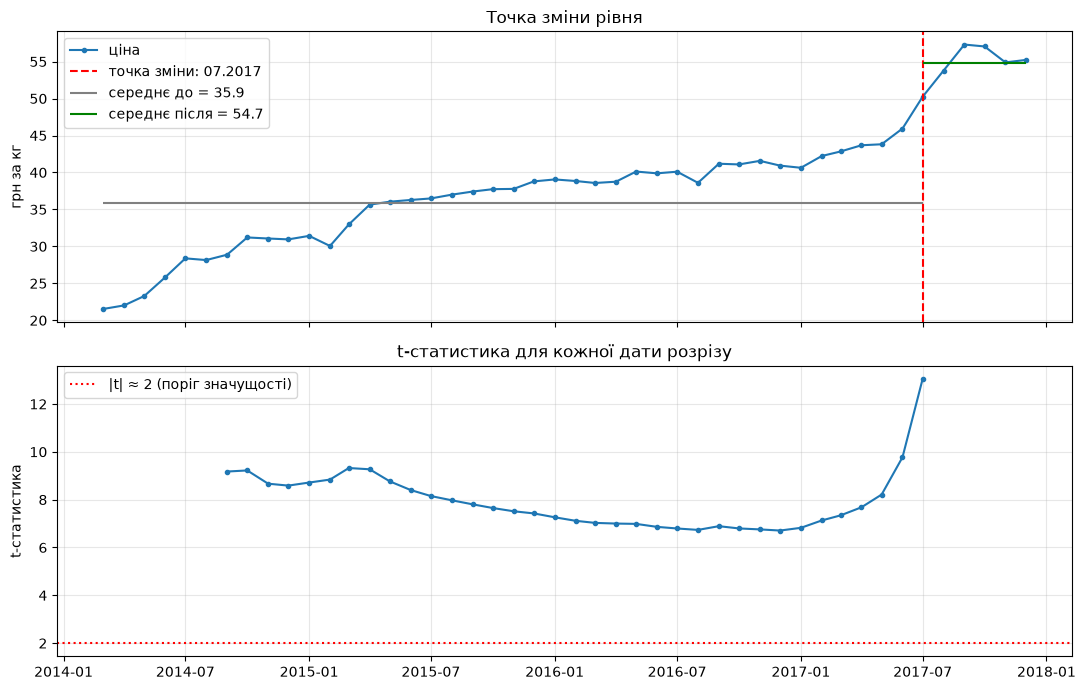

In [11]:
# Завдання 8. Точка зміни режиму
from scipy import stats

def scan(x, min_seg=6):
    """Для кожної дати порівнюємо середні до і після (t-тест Велча)"""
    rows = []
    for i in range(min_seg, len(x) - min_seg + 1):
        before, after = x.iloc[:i], x.iloc[i:]
        t, p = stats.ttest_ind(after, before, equal_var=False)
        rows.append({'date': x.index[i], 't': t, 'p': p,
                     'до': before.mean(), 'після': after.mean()})
    return pd.DataFrame(rows).set_index('date')

# Сканування рівня ряду
sc = scan(y)
best = sc['t'].abs().idxmax()
b = sc.loc[best]
print(f'Знайдена дата: {best:%m.%Y}')
print(f't = {b.t:.2f}, p = {b.p:.2e}')
print(f'Середнє до: {b["до"]:.2f} грн, після: {b["після"]:.2f} грн')
print(f'\nНайменша |t| серед УСІХ кандидатів: {sc["t"].abs().min():.2f}  → значущою виходить будь-яка дата')

# Перевірка без тренду: сканування змін ціни
sc_d = scan(y.diff().dropna())
best_d = sc_d['t'].abs().idxmax()
print(f'\nСканування першої різниці: найкраща дата {best_d:%m.%Y}, '
      f't = {sc_d.loc[best_d, "t"]:.2f}, p = {sc_d.loc[best_d, "p"]:.3f}')

# Чи подія 2017 року загальнонаціональна?
ch = prices[(prices['товар'] == GOOD) & (prices['рік'] == 2017)].pivot_table(
        index='ринок', columns='місяць', values='ціна')
growth = (ch[9] / ch[6] - 1) * 100
print(f'\nЗростання 06→09.2017 по {len(growth)} ринках: від {growth.min():.1f}% до {growth.max():.1f}%')

# Графіки
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(y.index, y.values, marker='o', ms=3, label='ціна')
axes[0].axvline(best, color='red', ls='--', label=f'точка зміни: {best:%m.%Y}')
axes[0].hlines(b['до'],    y.index[0], best,        colors='gray',  label=f'середнє до = {b["до"]:.1f}')
axes[0].hlines(b['після'], best,       y.index[-1], colors='green', label=f'середнє після = {b["після"]:.1f}')
axes[0].set_ylabel('грн за кг'); axes[0].set_title('Точка зміни рівня'); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(sc.index, sc['t'], marker='o', ms=3)
axes[1].axhline(2, color='red', ls=':', label='|t| ≈ 2 (поріг значущості)')
axes[1].set_ylabel('t-статистика'); axes[1].set_title('t-статистика для кожної дати розрізу')
axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Висновок до завдання 8:**

Сканування можливих дат зміни рівня ряду за допомогою t-тесту Велча показало найбільше значення для 07.2017: t = 13.05. Середня ціна до цієї дати становила 35,92 грн, а після - 54,75 грн. Формально p ≈ 6·10⁻¹⁰.

Однак це ще не доводить зміну режиму. Через постійне зростання ціни майже всі дати дають значущий результат. До того ж ряд має сильну автокореляцію, а серед 35 перевірених дат обрано ту, де результат найбільший. Перевірка першої різниці не виявила значущої зміни темпу зростання (max |t| = 1.56, p = 0.15). Тому статистично підтвердити точку зміни режиму не вдалося.

Водночас у червні-вересні 2017 року ціна справді різко зросла з 45,9 до 57,3 грн, приблизно на 25 %, і надалі залишалася на рівні 55-57 грн. Подібне зростання відбулося на всіх 26 ринках набору. На відміну від сезонного сплеску, ціна не повернулася до попереднього рівня, а залишилася вищою. Саме через цю одноразову подію STL у завданні 4 частково визначив сезонність, якої насправді може не бути.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [12]:
# Завдання 9. Перевірка двох тверджень, яких немає у виводі колеги
def series(market, good):
    return prices[(prices['ринок'] == market) & (prices['товар'] == good)].set_index('date')['ціна'].reindex(grid).interpolate()

buck, beef = series('Vinnytsia', 'Buckwheat grits - Retail'), series('Vinnytsia', 'Meat (beef) - Retail')
print(f'[3] Пік гречки: {buck.max():.2f} грн у {buck.idxmax():%m.%Y}, остання ціна: {buck.iloc[-1]:.2f} грн')
for name, x in [('гречка', buck), ('яловичина', beef)]:
    e = (x - x.shift(1)).dropna()
    print(f'[4] {name}: MAE = {e.abs().mean():.2f} грн, MAPE = {(e.abs() / x[1:]).mean() * 100:.1f} %')

[3] Пік гречки: 36.93 грн у 07.2016, остання ціна: 17.67 грн
[4] гречка: MAE = 1.35 грн, MAPE = 6.1 %
[4] яловичина: MAE = 1.47 грн, MAPE = 1.9 %


**Висновок до завдання 9:**

Зошит колеги запускається без помилок, але містить щонайменше 12 методологічних помилок:

| Клітинка          | Помилка                                                                                                                                                                                                   | Чим небезпечна                                                                               |
| ----------------- | --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------- |
| [1]               | Створено `grid`, але ряд не накладено на неї. Не помічено, що є 45 спостережень замість 46                                                                                                                | Пропуск залишається непоміченим                                                              |
| [2]               | Пропуски шукаються через `isna()` до `reindex`. Відсутній місяць 08.2017 не визначається як `NaN`                                                                                                         | Вересень стає сусідом липня, через що зміщуються лаги, STL та ARIMA                          |
| [3]               | Висновок зроблено лише за двома точками (першою й останньою); проміжна динаміка ігнорується, хоча графік у клітинці [2] показує, що ціна після піку суттєво знижувалась. Висновок про купівельну спроможність без даних про доходи        | Неправильне уявлення про динаміку та непідтверджений економічний висновок                    |
| [4]               | Порівнюються MAE двох товарів з різним рівнем цін; MAE залежить від масштабу, тому коректно порівнювати відносну похибку (MAPE)                                                                               | Неправильне порівняння точності прогнозів                                                    |
| [5]               | Кореляцію між двома рядами з трендом використано для висновку про причинність («визначають»)                                                                                                              | Причинний зв'язок не підтверджено                                                            |
| [6]               | Сезонність визначено лише тому, що STL виділив сезонну складову. Не обчислено F_S, а STL застосовано до ряду з пропуском                                                                                  | Неправильний вибір сезонних моделей                                                          |
| [7]               | ADF p = 0,233 помилково інтерпретовано як ознаку стаціонарності. Ряд, названий стаціонарним, продиференційовано двічі. Тест KPSS не використано                                                           | Неправильний вибір d і надмірне диференціювання                                              |
| [8]               | У коді використано поріг 1,3σ замість заявлених 2σ. Z-оцінка від загального середнього на ряді з трендом визначає 12 із 45 місяців як аномалії                                                            | Хибне визначення нетипових подій                                                             |
| [9]               | Використано випадковий поділ 75/25. ARIMA навчається на несуміжних точках, а прогноз порівнюється з відсортованими тестовими значеннями. MAE 8,73 названо високою точністю, хоча наївний прогноз дає 1,38 | Модель, яка приблизно у 6 разів гірша за найпростіший прогноз, рекомендована до використання |
| [10]              | Прогноз побудовано за іншою, неперевіреною моделлю ARIMA(2,2,1). Прогноз 8,95 грн за останньої ціни 17,67 грн названо зростанням. Довірчого інтервалу немає                                               | Висновок суперечить самому прогнозу                                                          |
| Загальні висновки | Повторюють усі помилкові результати без застережень                                                                                                                                                       | Помилки потрапляють у підсумкові висновки                                                    |

Три найсерйозніші помилки та способи їх виправлення:

1. Клітинка [9] - перевірка моделі. Замість випадкового поділу та сортування потрібно використати ретроспективну перевірку з рухомим початком: навчати модель на всіх даних до моменту прогнозу, прогнозувати на кілька кроків уперед і повторювати перевірку для різних періодів. ARIMA обов'язково потрібно порівняти з наївним прогнозом і прогнозом за дрейфом на однакових фолдах.
2. Клітинка [7] - стаціонарність. Правильно трактувати ADF: якщо p ≥ 0,05, немає достатніх підстав відхилити гіпотезу про нестаціонарність. Також потрібно перевірити результат KPSS і диференціювати ряд по одному разу, перевіряючи результат після кожного кроку, щоб уникнути надмірного диференціювання.
3. Клітинки [1]-[2] - прихований пропуск. Потрібно накласти ряд на повну місячну сітку через `reindex(grid)` і лише після цього шукати пропуски. Відсутнє значення за 08.2017 слід заповнити обґрунтованим методом, наприклад лінійною інтерполяцією.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [13]:
# Завдання 10. Експорт ряду для Orange
out = pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'),
                    'price': y.values})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

# Перевірка: читаємо файл назад
check = pd.read_csv('ряд_для_orange.csv')
print('Стовпці:', list(check.columns))
print('Рядків даних:', len(check))
print('Порожніх значень:', check.isna().sum().sum())
print('Перша і остання дата:', check['date'].iloc[0], '…', check['date'].iloc[-1])
print('Збігається з рядом у Python:', np.allclose(check['price'], y.values))
print(check.loc[check['date'] == '2017-08-01'])

Стовпці: ['date', 'price']
Рядків даних: 46
Порожніх значень: 0
Перша і остання дата: 2014-03-01 … 2017-12-01
Збігається з рядом у Python: True
          date     price
41  2017-08-01  53.77665


**Висновок до завдання 10:**

Підготовлений ряд із пропуском за 08.2017, заповненим лінійною інтерполяцією, збережено у файл `ряд_для_orange.csv`. Файл має потрібний формат: стовпці `date` (дата у форматі `РРРР-ММ-ДД`, перше число місяця) і `price` (ціна), роздільник - кома, кодування UTF-8. Повторна перевірка підтвердила наявність 46 рядків даних за період 03.2014–12.2017 без порожніх значень. Ціни збігаються з даними Python, зокрема за 08.2017 - 53,77665 грн. Значення не округлювали, щоб Orange отримав ті самі дані, що й Python, а відмінності в метриках у частині 2 пояснювалися лише різницею в їхніх означеннях.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

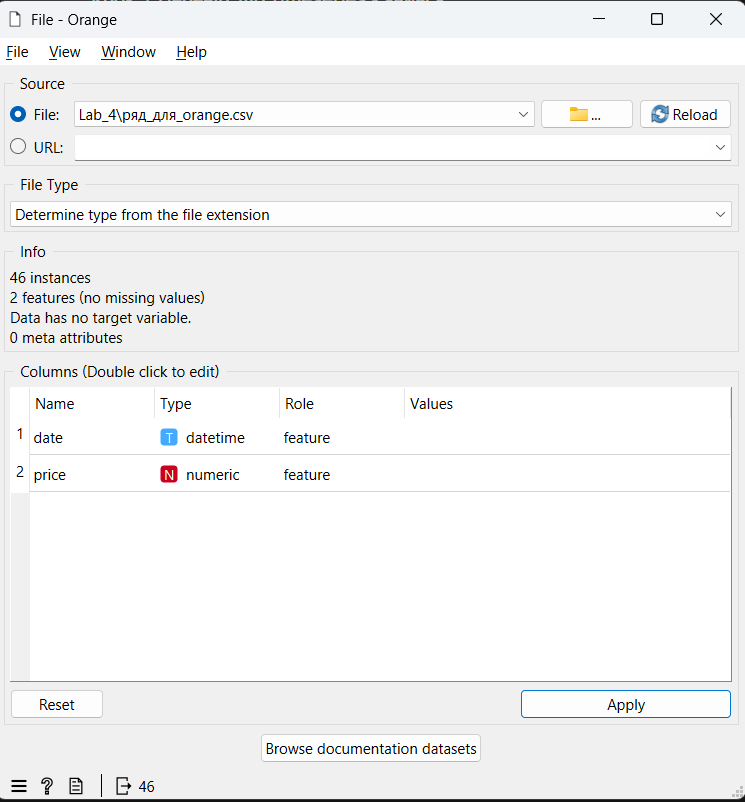

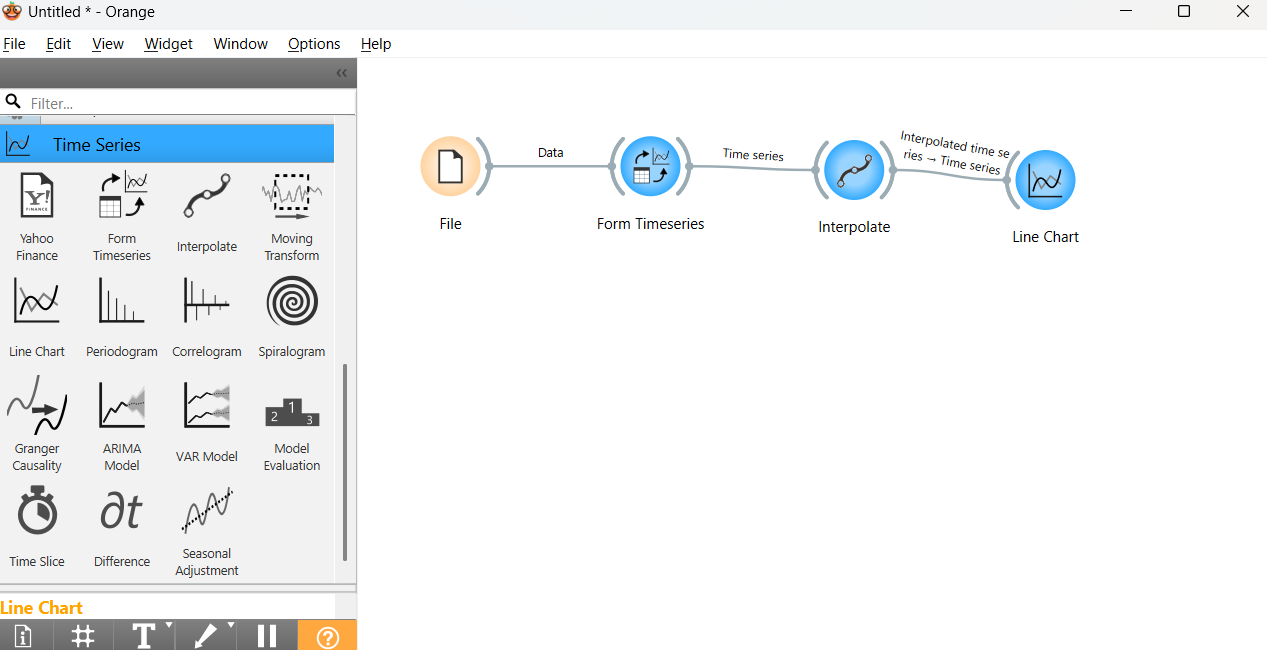

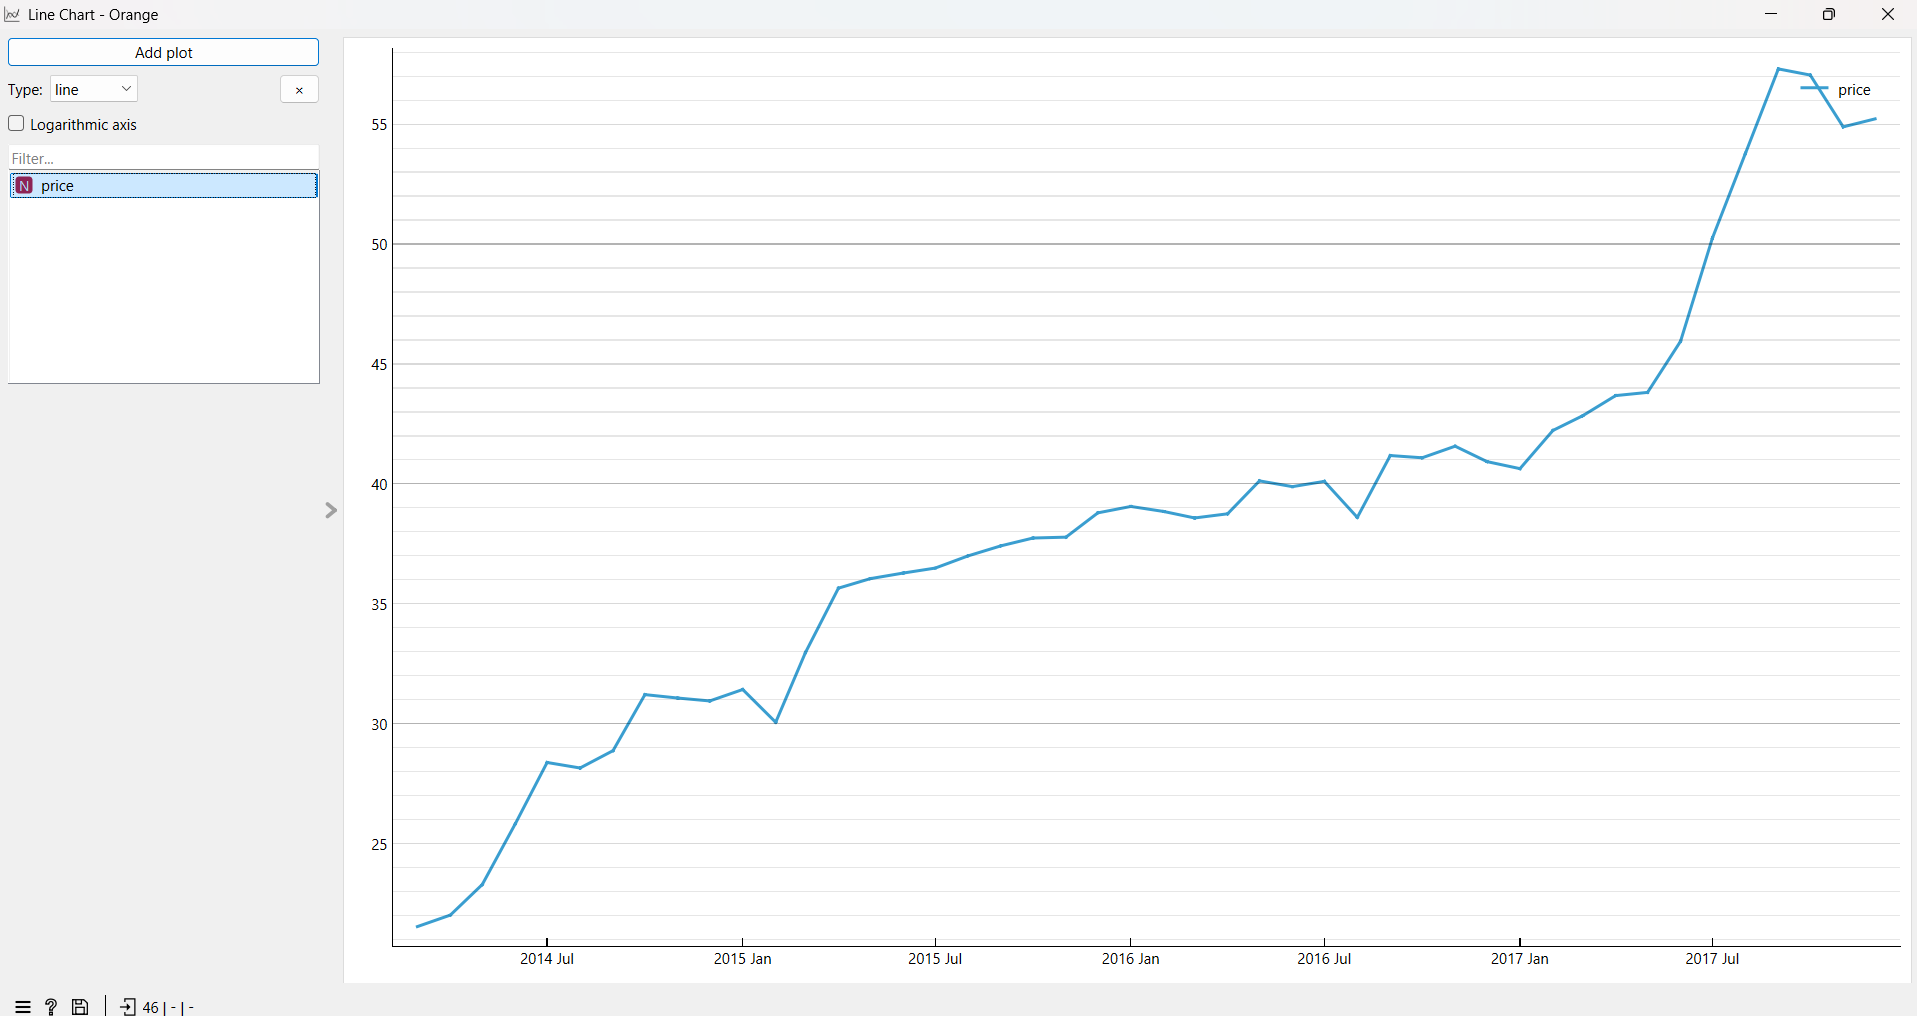

In [14]:
# Завдання 11. Потік опрацювання даних

**Висновок до завдання 11:**

В Orange побудовано потік `File → Form Timeseries → Interpolate → Line Chart`. Віджет File завантажив `ряд_для_orange.csv`: 46 спостережень, 2 змінні без пропусків. `date` розпізнано як дату й час, а `price` - як числову змінну. У Form Timeseries обрано `date` як часову змінну, а Interpolate не знайшов пропусків, оскільки значення за 08.2017 вже заповнено в Python лінійною інтерполяцією. Отже, Orange отримує той самий ряд. Графік Line Chart збігається з графіком 1 із завдання 3: ціна зростає приблизно з 21,5 грн у 03.2014, у 2016 році тримається на рівні 39-41 грн, а в червні-вересні 2017 року різко зростає до 57 грн. Це підтверджує, що обидва середовища працюють з однаковими даними.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

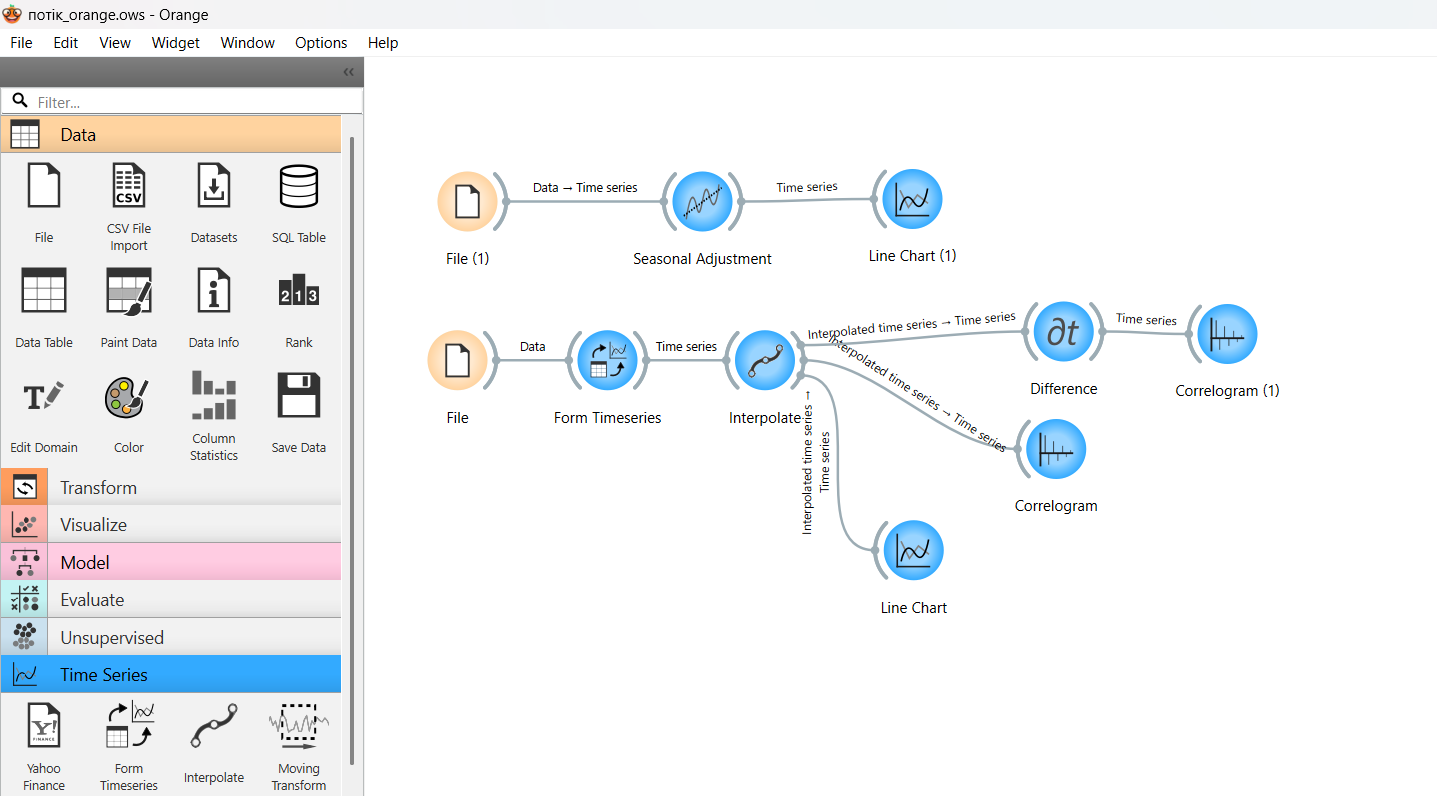

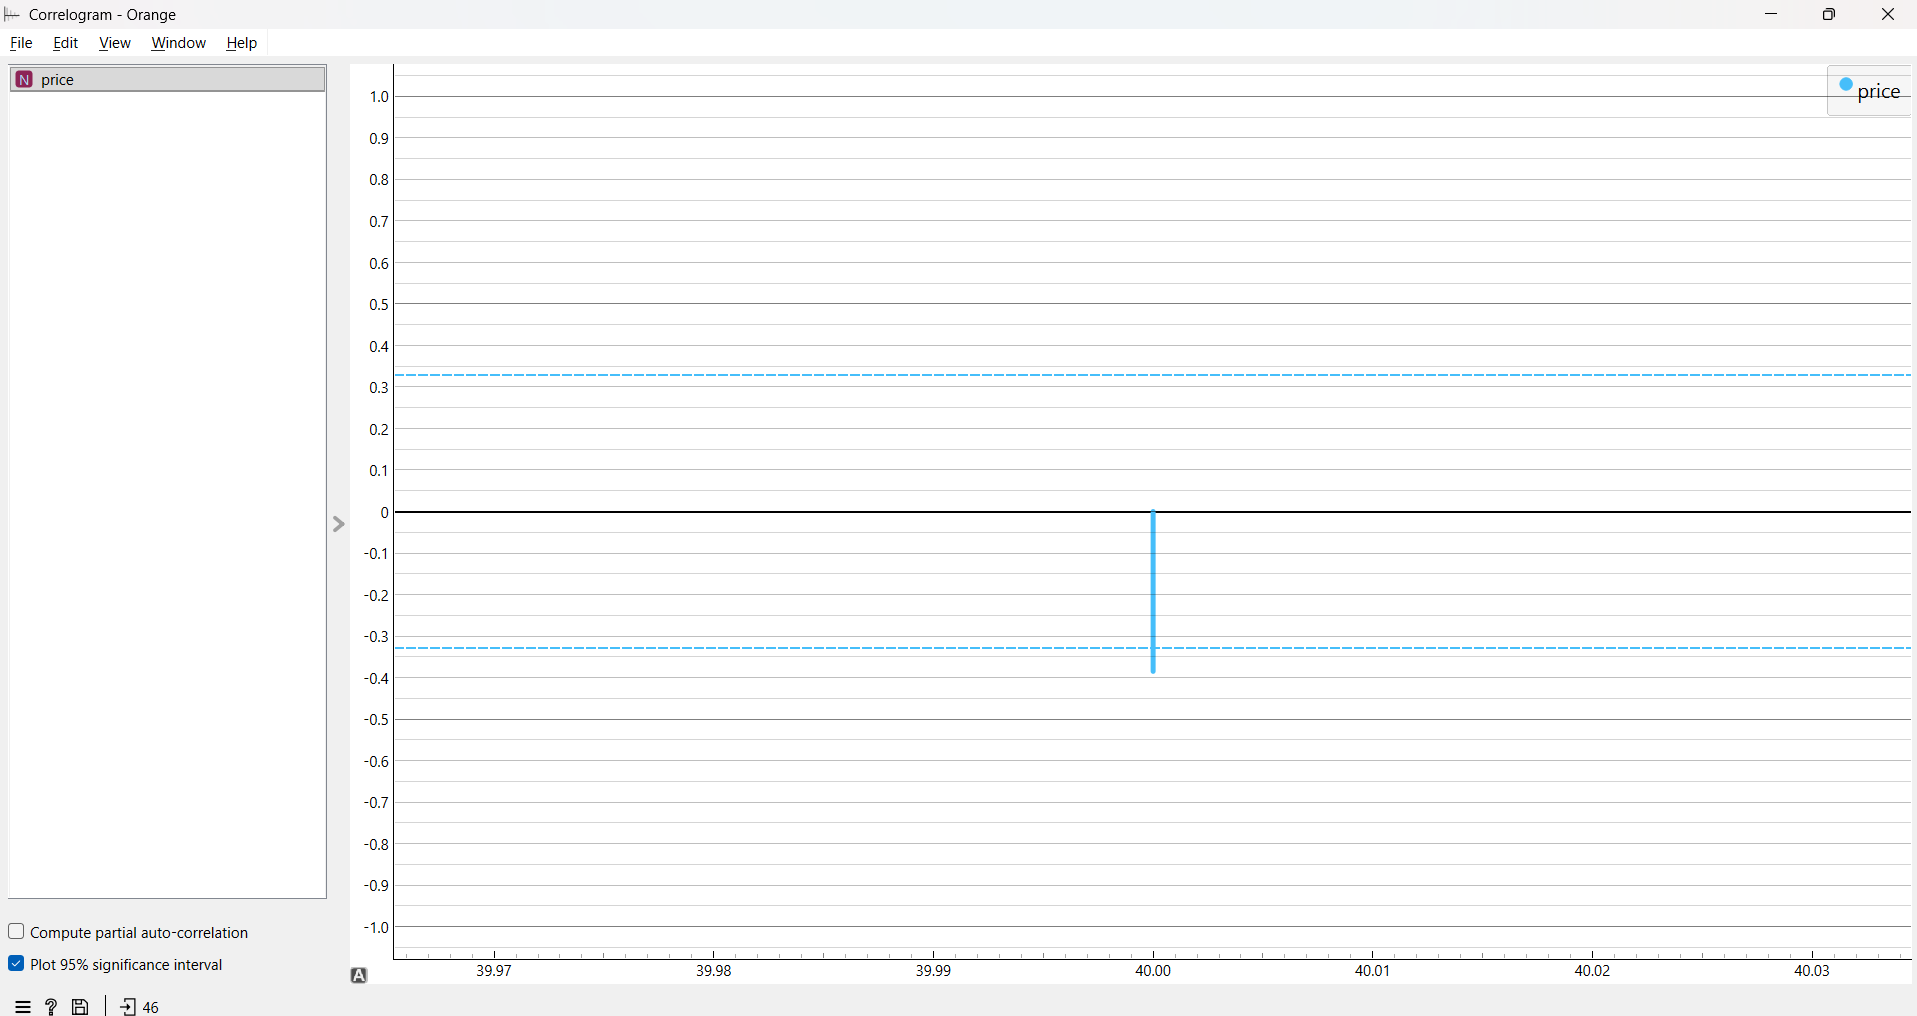

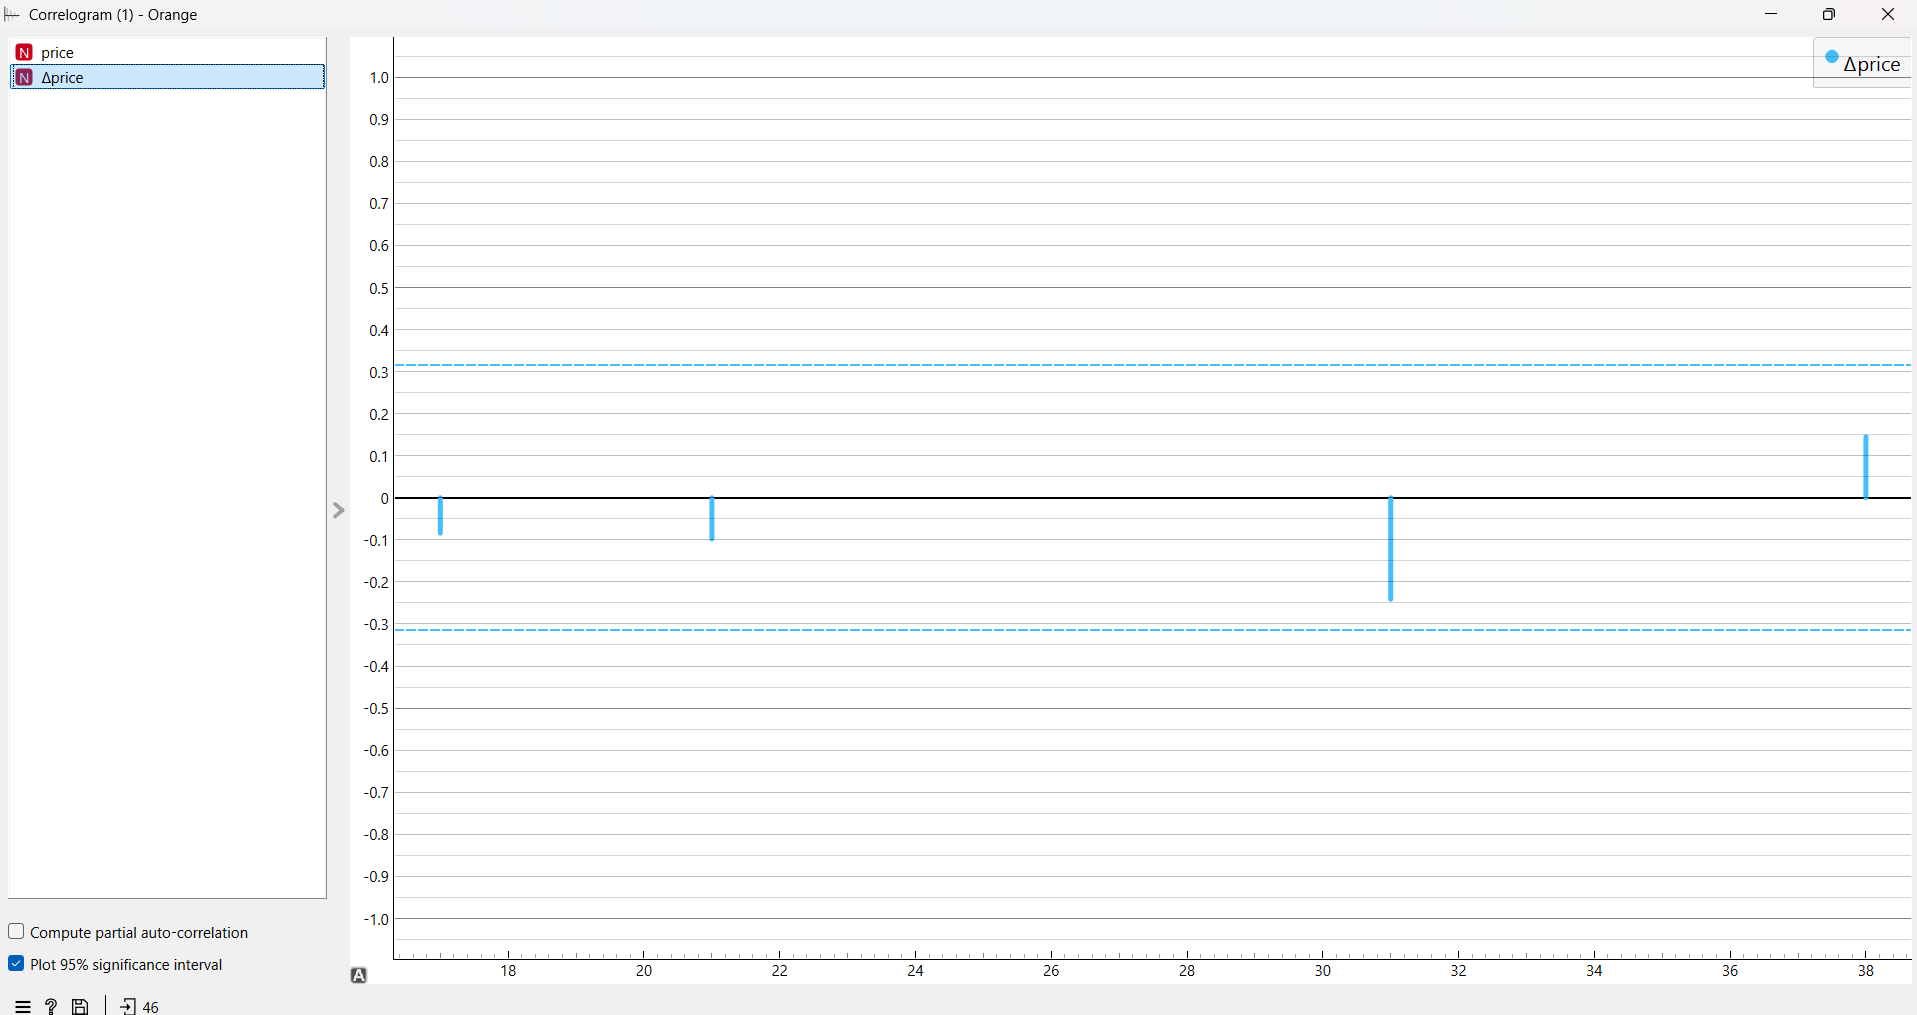

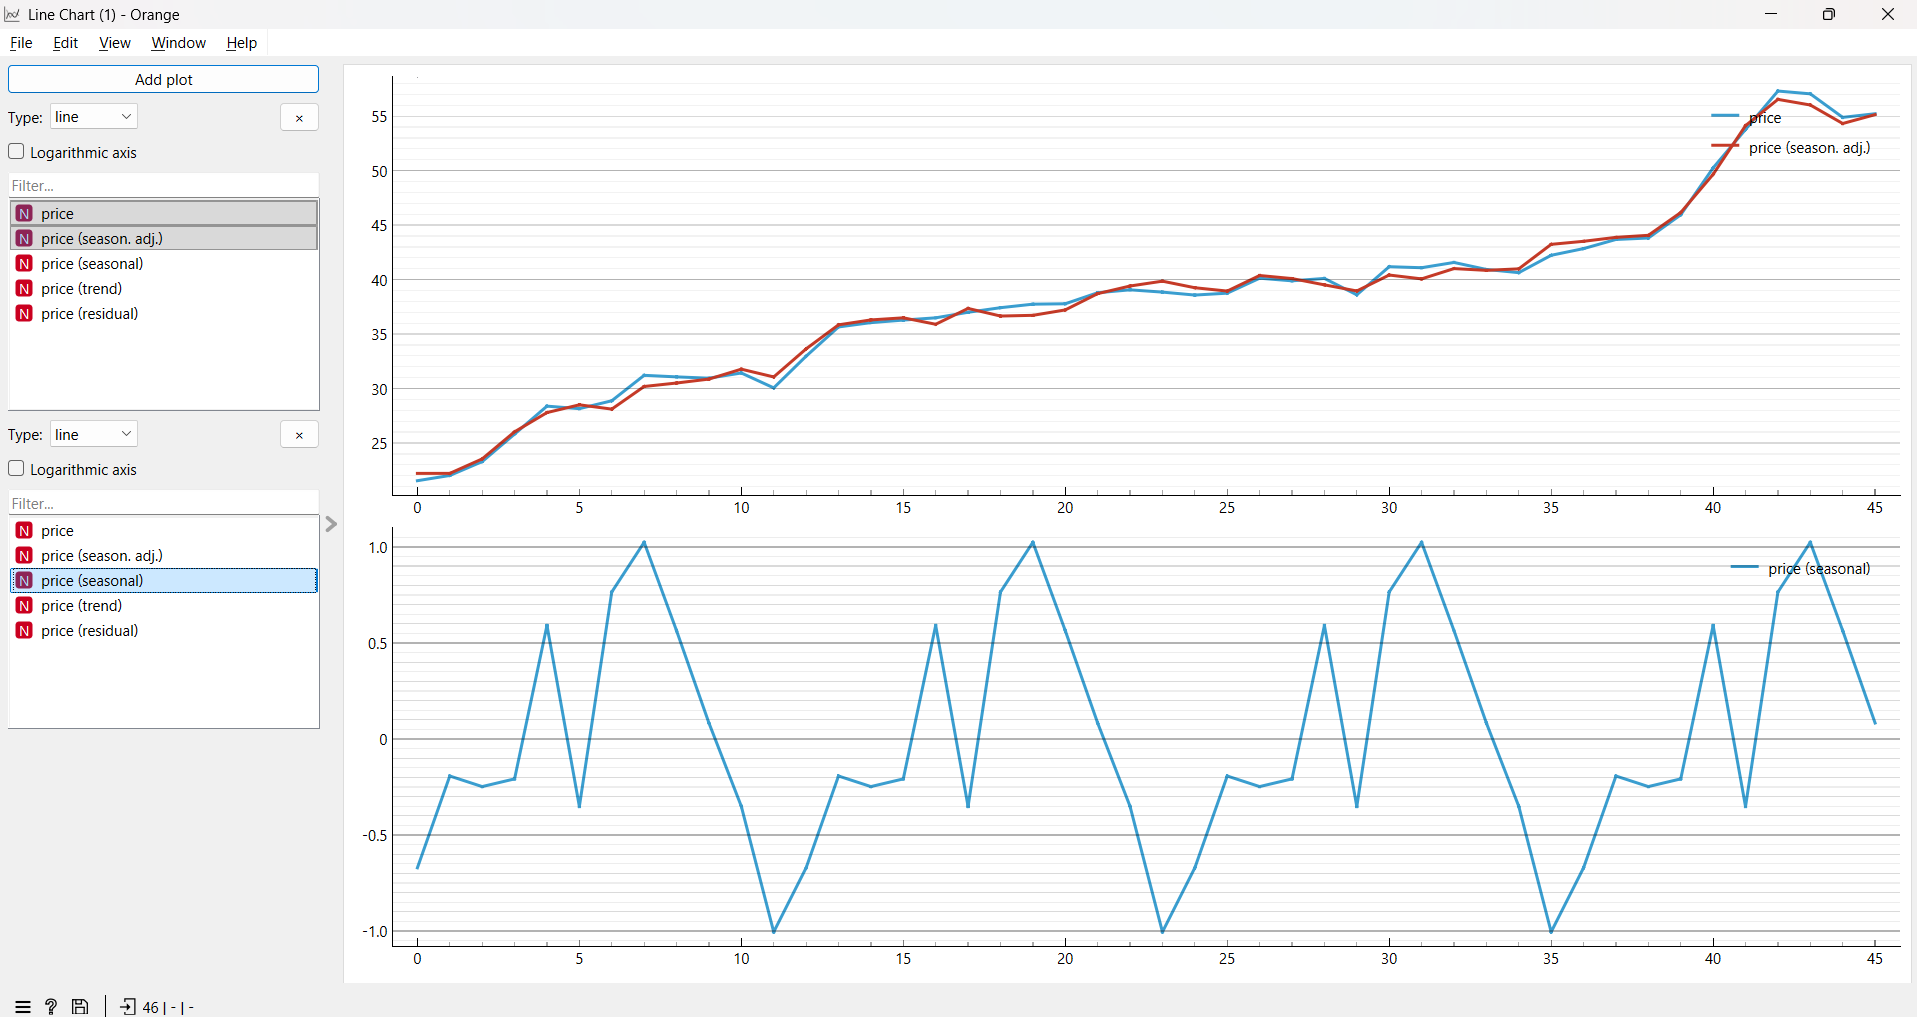

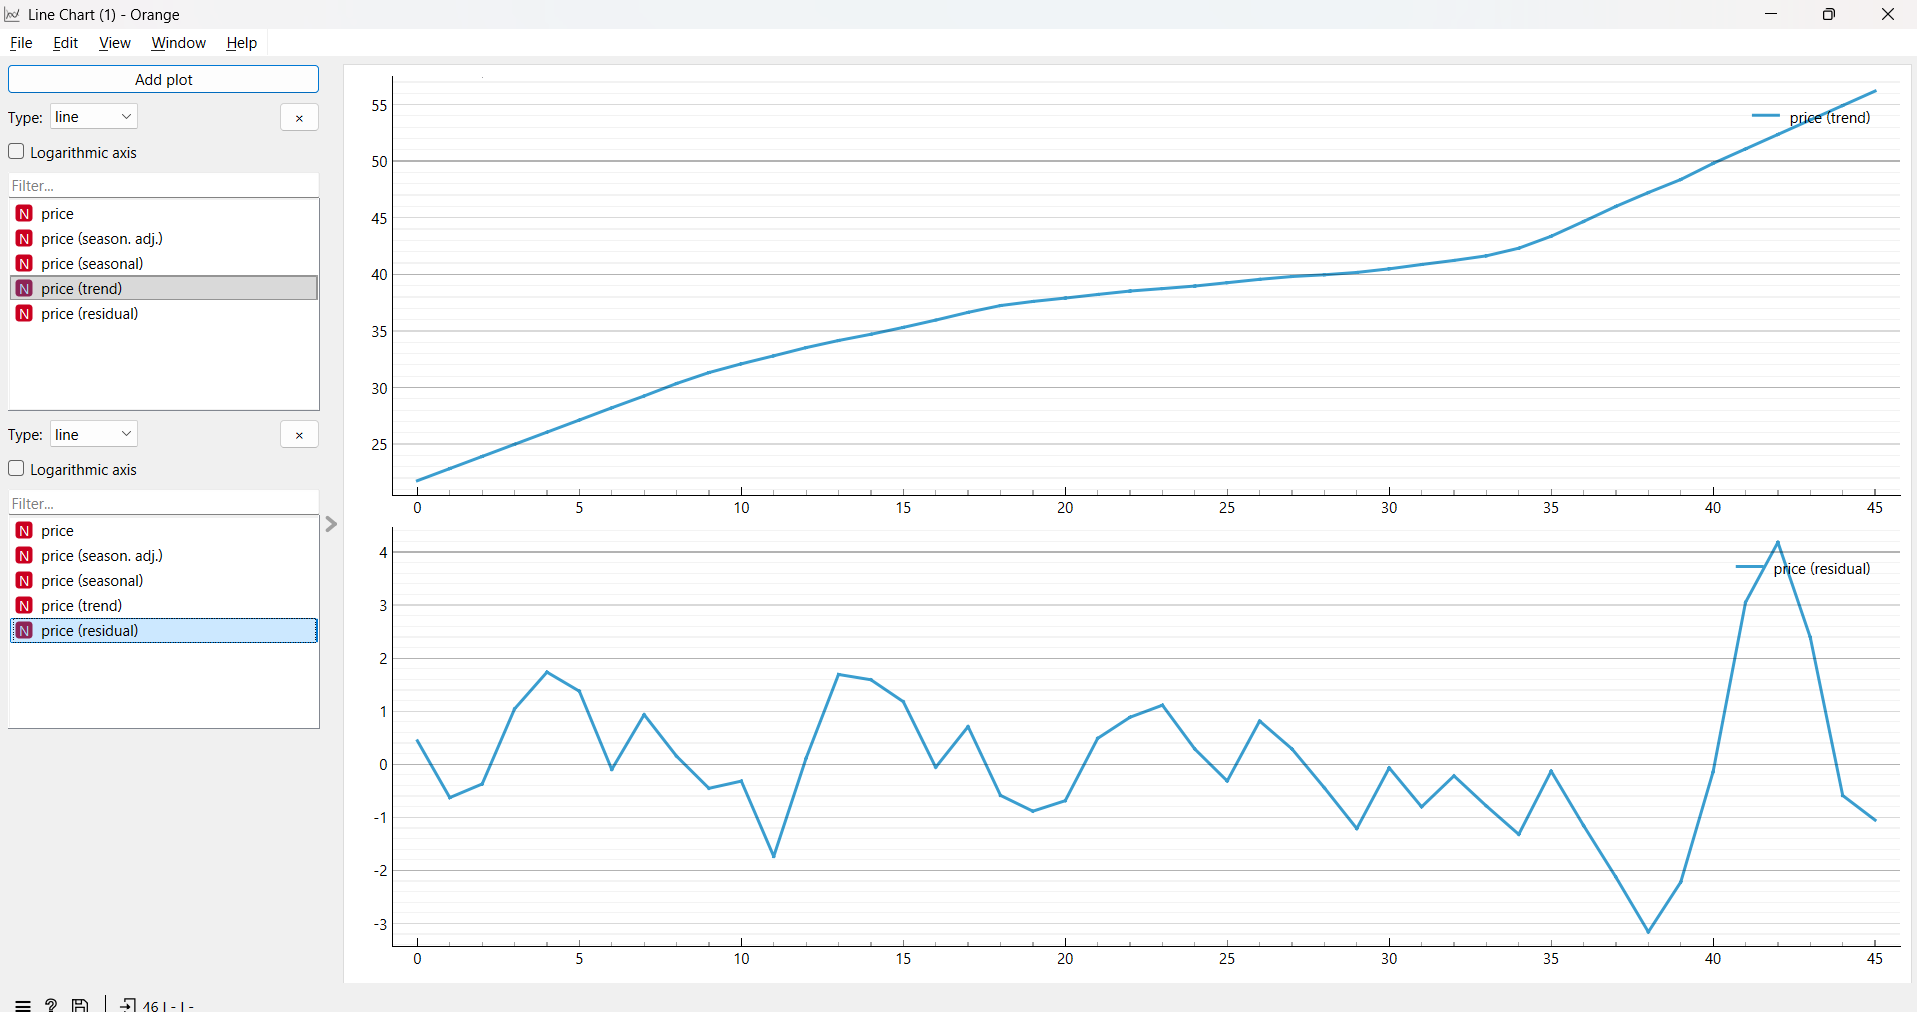

In [15]:
# Завдання 12. Автокореляція та диференціювання

**Висновок до завдання 12:**

До потоку додано `Correlogram` для вихідного ряду, `Difference` для першої різниці та `Seasonal Adjustment` з періодом 12 і адитивною моделлю. Корелограма вихідного ряду. Orange показує лише локальні піки автокореляції, тому не відображає лаги 1-3, хоча в statsmodels вони значущі (0,90; 0,79; 0,67). На лагу 40 значення становить приблизно −0,385, як і в statsmodels. Різниця у висновках пов'язана зі способом відображення лагів і межами значущості. Корелограма першої різниці. Найбільша автокореляція за модулем становить приблизно −0,245 на лагу 31 і не виходить за межу значущості. Результат збігається зі statsmodels: після першого диференціювання значущої автокореляції немає, а лаг 12 не вказує на сезонність. Сезонне коригування. Через помилку Orange часову змінну `date` довелося виключити з окремого файлу, тому на графіку показано номери спостережень. Сезонна складова класичного розкладання збігається зі statsmodels і коливається приблизно від −1 грн у лютому до +1 грн у жовтні. Тому скоригований ряд майже не відрізняється від вихідного. На відміну від STL, класичне розкладання відносить стрибок 2017 року до залишку, а не до сезонності. Обидва методи показують, що сезонність слабка, а основний вплив мають тренд і різке зростання ціни у 2017 році.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

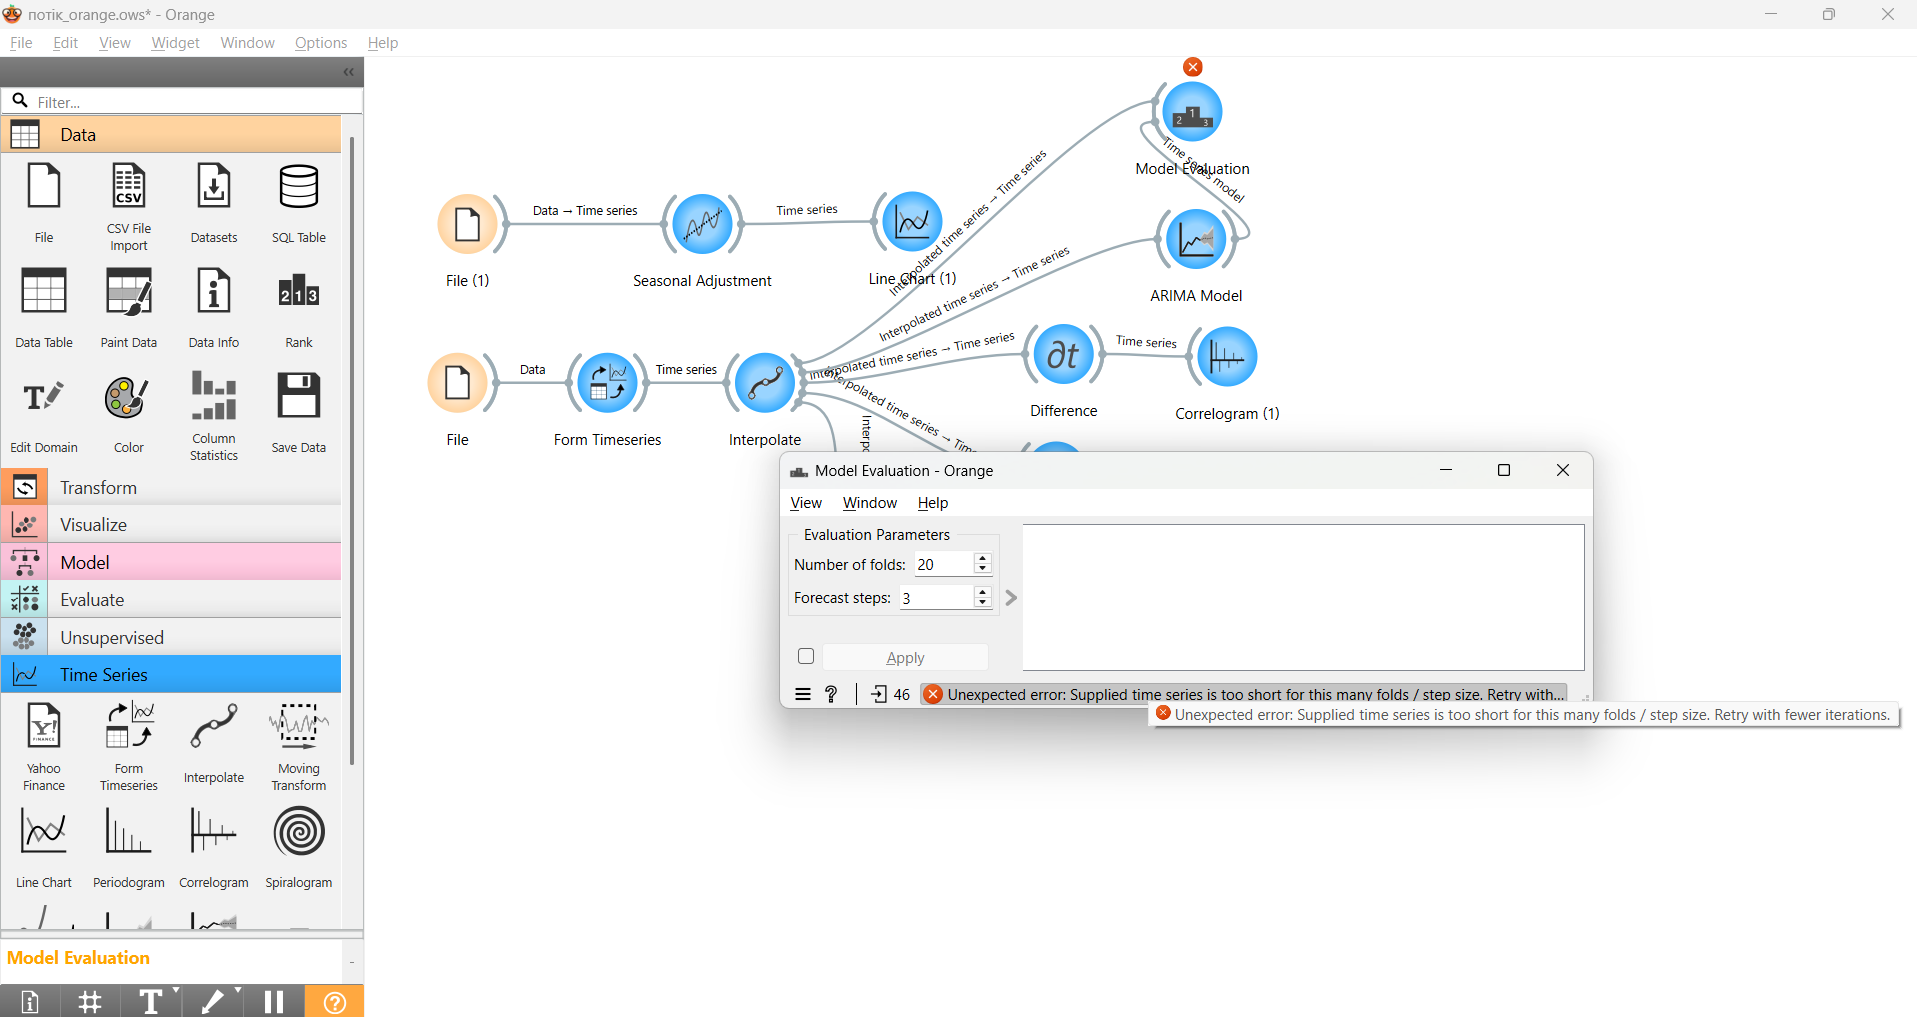
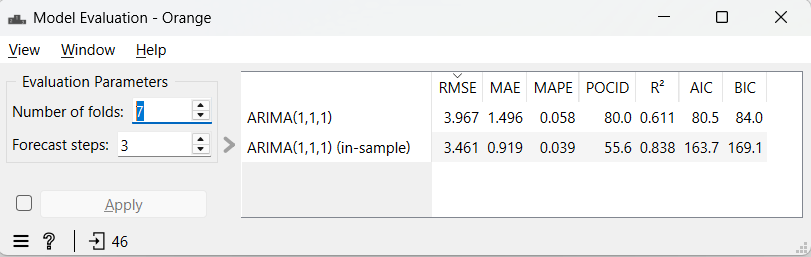

In [16]:
# Завдання 13. Модель і оцінювання

**Висновок до завдання 13:**

До потоку додано `ARIMA Model` з порядком (1, 1, 1) і `Model Evaluation`. Змінній `price` призначено роль цільової. Для 7 фолдів по 3 кроки метрики такі: RMSE = 3,967, MAE = 1,496, MAPE = 0,058, POCID = 80%, R² = 0,611. Також наведено похибки на навчальних даних, AIC і BIC. За типових налаштувань (20 фолдів × 3 кроки) Orange видає помилку `Supplied time series is too short for this many folds / step size. Retry with fewer iterations.`, оскільки потрібно 61 спостереження, а є лише 46. Максимум для 3 кроків - 15 фолдів. Orange перевіряє 7 фолдів: 1) навчання 03.2014–09.2017, тест 10–12.2017; 2) навчання до 06.2017, тест 07–09.2017; 3) до 03.2017, тест 04–06.2017; 4) до 12.2016, тест 01–03.2017; 5) до 09.2016, тест 10–12.2016; 6) до 06.2016, тест 07–09.2016; 7) до 03.2016, тест 04–06.2016. Це ті самі фолди з розширюваною навчальною частиною, що й у Python, але в зворотному порядку. Тому різниця в метриках може бути пов'язана лише з особливостями їх обчислення.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [17]:
# Завдання 14. Відтворення метрик Orange

# Збираємо прогнози ARIMA(1,1,1) у тому ж порядку, що й Orange
true_o, pred_o = [], []
for tr, te in reversed(folds):
    true_o.extend(te.values)
    pred_o.extend(arima_forecast(tr, H, (1, 1, 1)))
true_o, pred_o = np.array(true_o), np.array(pred_o)
err = true_o - pred_o

# Формули Orange
orange = {
    'RMSE':  np.sqrt(np.mean(err ** 2)),
    'MAE':   np.median(np.abs(err)), # медіана, а не середнє
    'MAPE':  np.mean(np.abs(err)) / np.abs(true_o).mean(), # частка, середнє|e| / середнє|y|
    'POCID': 100 * np.mean(np.diff(true_o) * np.diff(pred_o) > 0),
}
# Класичні формули
classic = {
    'RMSE':  np.sqrt(np.mean(err ** 2)),
    'MAE':   np.mean(np.abs(err)),
    'MAPE':  np.mean(np.abs(err / true_o)) * 100,
}
orange_table = {'RMSE': 3.967, 'MAE': 1.496, 'MAPE': 0.058, 'POCID': 80.0}

table = pd.DataFrame({
    'Orange (таблиця)':      orange_table,
    'Відтворення в Python':  {k: round(v, 3) for k, v in orange.items()},
    'Класична формула':      {k: round(v, 3) for k, v in classic.items()},
    'Формула Orange': {
        'RMSE':  'sqrt(mean(e²))',
        'MAE':   'median(|e|)',
        'MAPE':  'mean(|e|) / mean(|y|)',
        'POCID': '100·mean(Δy·Δŷ > 0)',
    },
})
print(table.to_string())

print('\nАбсолютні помилки за зростанням:', np.sort(np.abs(err)).round(2))
chrono = np.argsort(np.concatenate([te.index.values for tr, te in reversed(folds)]))
print('POCID при хронологічному порядку фолдів:',
      round(100 * np.mean(np.diff(true_o[chrono]) * np.diff(pred_o[chrono]) > 0), 1))

       Orange (таблиця)  Відтворення в Python  Класична формула         Формула Orange
RMSE              3.967                 3.967             3.967         sqrt(mean(e²))
MAE               1.496                 1.496             2.615            median(|e|)
MAPE              0.058                 0.058             5.170  mean(|e|) / mean(|y|)
POCID            80.000                80.000               NaN    100·mean(Δy·Δŷ > 0)

Абсолютні помилки за зростанням: [0.19 0.41 0.45 0.52 0.55 0.58 0.74 0.75 0.93 1.08 1.5  1.61 1.71 1.71
 1.94 2.87 3.76 6.75 7.53 9.6  9.73]
POCID при хронологічному порядку фолдів: 70.0


**Висновок до завдання 14:**

MAE в Orange насправді є медіаною абсолютних похибок, тому дає 1,496 грн замість середнього 2,615 грн. MAPE рахується за іншою формулою і становить 0,058 (≈5,8%). POCID залежить від порядку об'єднання прогнозів: в Orange він дорівнює 80%, а при хронологічному порядку - 70%. RMSE збігається з Python, бо формула однакова. Отже, перед порівнянням результатів потрібно перевірити дані, модель, фолди та формули метрик. У цьому випадку перші три умови збігаються, а різниця виникає через спосіб обчислення метрик.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [18]:
# Завдання 15. Матриця напрямку зміни
def direction_matrix(actual_change, pred_change):
    return pd.crosstab(
        pd.Series(np.where(actual_change > 0, 'зросла', 'впала'), name='факт'),
        pd.Series(np.where(pred_change > 0, 'зросте', 'впаде'), name='прогноз'))

# Як рахує Orange (POCID): напрямок між сусідніми точками склеєних фолдів
d_true, d_pred = np.diff(true_o), np.diff(pred_o)
m_pocid = direction_matrix(d_true, d_pred)
print('Матриця для POCID (20 пар сусідніх точок):')
print(m_pocid)
print(f'Частка правильних: {np.trace(m_pocid.values)}/{m_pocid.values.sum()} = '
      f'{np.trace(m_pocid.values) / m_pocid.values.sum() * 100:.1f}%  (POCID в Orange = 80.0)')

# Рішення «купувати зараз чи чекати»: порівняння з останньою відомою ціною
last_known = np.concatenate([np.repeat(tr.iloc[-1], H) for tr, te in reversed(folds)])
m_buy = direction_matrix(true_o - last_known, pred_o - last_known)
acc_buy = np.trace(m_buy.values) / m_buy.values.sum() * 100
always_up = np.mean(true_o - last_known > 0) * 100
print('\nМатриця «вища чи нижча за сьогоднішню ціну» (21 прогноз):')
print(m_buy)
print(f'Точність ARIMA(1,1,1): {acc_buy:.1f}%')
print(f'Правило «ціна завжди зросте»: {always_up:.1f}%')

Матриця для POCID (20 пар сусідніх точок):
прогноз  впаде  зросте
факт                  
впала        7       3
зросла       1       9
Частка правильних: 16/20 = 80.0%  (POCID в Orange = 80.0)

Матриця «вища чи нижча за сьогоднішню ціну» (21 прогноз):
прогноз  впаде  зросте
факт                  
впала        1       6
зросла       5       9
Точність ARIMA(1,1,1): 47.6%
Правило «ціна завжди зросте»: 66.7%


**Висновок до завдання 15:**

POCID в Orange порівнює напрямок змін факту й прогнозу та становить 80% (16 правильних із 20 пар). Але для рішення «купувати зараз чи чекати» важливо порівнювати прогноз із поточною ціною. У такому випадку модель правильно визначила напрямок лише у 47,6% випадків, тоді як просте правило «ціна зростатиме, купуй зараз» дало б 66,7%. Тому ARIMA(1,1,1) не підходить для такого рішення, попри високий POCID. Після стрибка 2017 року модель прогнозувала подальше зростання, але ціна знизилася. MAE та RMSE показують розмір похибки в гривнях, а POCID - правильність напрямку. Тому модель потрібно оцінювати за метриками, які відповідають конкретному рішенню.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

Стійкої сезонності в ряді немає: звичайне STL дало F_S = 0.673, але робастне STL лише 0.045, а сезонна складова не повторювалася, а наростала з року в рік. Ряд визначається сильним висхідним трендом (F_T = 0.985), і після одного диференціювання стає стаціонарним, що підтвердили обидва тести, ADF і KPSS.  
Найкращим методом прогнозу виявився найпростіший базис, дрейф (MAE = 1.99 грн), а ARIMA(1,1,1) йому програла (MAE = 2.62 грн) і не дала переваги навіть над наївним прогнозом.  
Статистично значущу точку зміни режиму довести не вдалося, бо через тренд «значущою» виходить будь-яка дата. Проте влітку 2017 року ціна різко зросла на 25 % і не повернулася назад, причому одночасно на всіх 26 ринках, тож це загальнонаціональна подія на ринку курятини.  
Однаково названі метрики в Python і Orange дали різні числа, бо мають різні формули: «MAE» в Orange насправді є медіаною похибок, а «MAPE» ділить середню похибку на середню ціну й подається часткою, а не у відсотках.  
Через те, що ряд має лише 46 спостережень (менше чотирьох повних років), не вдалося надійно перевірити сезонність і точку зміни режиму, а модель у перших фолдах навчалася лише на 25 точках. Також через короткий ряд Orange не дозволив використати більше 15 фолдів, а тест KPSS повертав p-value лише на межах своєї таблиці.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic), Claude Opus 5.5 |
| Для яких саме завдань | Пояснення теорії, допомога з кодом, висновками та роботою в Orange, пошук формул метрик. |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Пояснення понять, приклади коду та чернетки висновків. |
| Що ви змінили у згенерованому результаті й чому | Скоротив код, прибрав зайві перевірки, спростив висновки та переписав їх своїми словами. Також виправив неточності після перевірки результатів. |
| Що з отриманого ви **перевірили самостійно** і яким способом | Запустив код, перевірив результати та порівняв графіки й метрики Orange з Python. |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | 	Була неправильна назва віджета, не одразу вдалося виправити помилку Seasonal Adjustment, а також були неточності щодо меж значущості та відображення лагів у Correlogram. |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: 28.10.2026